# CR06 - Cutoff economics (LendingClub)

Goal: which PD cutoff maximizes expected profit? A loan is approved when its PD is at or below
the cutoff. The PD comes from the CR02 monotone LightGBM challenger, trained on loans issued
2007 to 2014 and scored on loans issued 2015 to 2016.

Profit per approved loan (per unit of exposure, EAD):
`(1 - PD) * margin - PD * LGD`. LGD and margin are stated assumptions, not data.
A loan is worth approving when PD < margin / (margin + LGD), the breakeven PD.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from credit_core.economics import cutoff_profit, expected_loss
from credit_core.metrics import gini
from credit_core.plots import plot_profit_curve
from cutoff_econ.econ import best_cutoff, breakeven_pd, sensitivity_grid
from cutoff_econ.pipeline import load_test_book

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Scores and exposure on the test window

In [2]:
book = load_test_book()
good_score = 1.0 - book.pd_
print(f"Test loans: {len(book.pd_):,}")
print(f"Observed bad rate (resolved only): {book.defaulted.mean():.3f}")
print(f"Mean PD: {book.pd_.mean():.3f}")
print(f"Gini (challenger, test): {gini(1 - book.defaulted, good_score):.3f}")
print(f"Total EAD: {book.ead.sum():,.0f}")

Test loans: 668,651
Observed bad rate (resolved only): 0.215
Mean PD: 0.171
Gini (challenger, test): 0.430
Total EAD: 9,738,962,750


## 2. Assumptions

Base case: LGD = 0.80 of EAD (low recoveries on unsecured consumer loans) and margin = 0.12 of EAD
on a repaid loan (interest earned over the loan life). Both are assumptions. Section 4 varies them.

In [3]:
LGD, MARGIN = 0.80, 0.12
BREAKEVEN = breakeven_pd(MARGIN, LGD)
print(f"Breakeven PD at LGD={LGD}, margin={MARGIN}: {BREAKEVEN:.4f}")

Breakeven PD at LGD=0.8, margin=0.12: 0.1304


## 3. Profit curve and optimal cutoff

In [4]:
cutoffs = np.arange(0.01, 0.601, 0.005)
table = cutoff_profit(book.pd_, book.defaulted, book.ead, margin=MARGIN, lgd=LGD, cutoffs=cutoffs)
best = best_cutoff(table)
print(f"Optimal cutoff (expected profit): PD <= {best['cutoff_pd']:.3f}")
print(f"Approval rate at optimum: {best['approval_rate']:.1%}")
print(f"Expected profit at optimum: {best['expected_profit']:,.0f}")
print(f"Realized profit at optimum: {best['realized_profit']:,.0f}")
print(f"Expected loss at optimum: {expected_loss(book.pd_[book.pd_ <= best['cutoff_pd']], LGD, book.ead[book.pd_ <= best['cutoff_pd']]).sum():,.0f}")

Optimal cutoff (expected profit): PD <= 0.130
Approval rate at optimum: 44.4%
Expected profit at optimum: 188,333,097
Realized profit at optimum: 104,492,375
Expected loss at optimum: 254,372,924


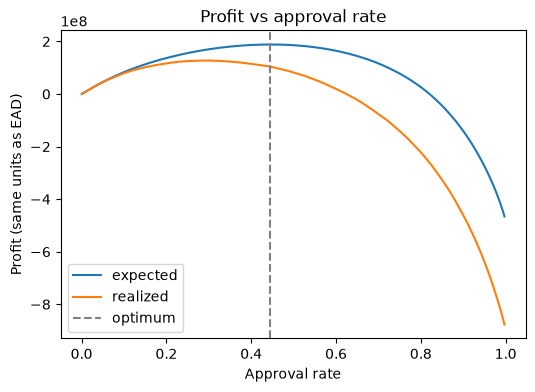

In [5]:
fig = plot_profit_curve(table)
fig.axes[0].axvline(best["approval_rate"], color="grey", linestyle="--", label="optimum")
fig.axes[0].legend()
fig.savefig(FIG_DIR / "cr06_profit_curve.png", dpi=120, bbox_inches="tight")
plt.show()

In [6]:
last = table.iloc[-1]
print(f"Widest cutoff PD <= {last['cutoff_pd']:.3f}: approval {last['approval_rate']:.1%}, "
      f"expected profit {last['expected_profit']:,.0f}, realized profit {last['realized_profit']:,.0f}")
print(f"Calibration check: mean PD {book.pd_.mean():.3f} vs observed bad rate {book.defaulted.mean():.3f}")

Widest cutoff PD <= 0.600: approval 99.7%, expected profit -465,746,104, realized profit -876,888,403
Calibration check: mean PD 0.171 vs observed bad rate 0.215


The expected-profit curve peaks at the breakeven PD, where expected profit is about 188M. Realized
profit at the same cutoff is about 104M, roughly half of that. The mean PD (0.171) is below the
observed bad rate (0.215), so the challenger under-predicts defaults on this window. This matches
the rising bad rate found in CR05. Expected profit is therefore optimistic, and the cutoff should
not be set from it alone.

## 4. Sensitivity to LGD and margin

In [7]:
lgds = [0.60, 0.70, 0.80]
margins = [0.08, 0.12, 0.16]
grid = sensitivity_grid(book.pd_, book.defaulted, book.ead, cutoffs, lgds, margins)
print(grid.round(4).to_string(index=False))

 lgd  margin  breakeven_pd  best_cutoff  approval_rate  expected_profit  realized_profit
 0.6    0.08        0.1176        0.120         0.3990     1.062592e+08       53421247.0
 0.6    0.12        0.1667        0.165         0.5818     2.689461e+08      161572617.0
 0.6    0.16        0.2105        0.210         0.7142     4.800796e+08      315576383.0
 0.7    0.08        0.1026        0.105         0.3280     8.390184e+07       41025170.0
 0.7    0.12        0.1463        0.145         0.5065     2.241032e+08      129377280.0
 0.7    0.16        0.1860        0.185         0.6469     4.137762e+08      259469691.0
 0.8    0.08        0.0909        0.090         0.2552     6.728864e+07       36751924.0
 0.8    0.12        0.1304        0.130         0.4438     1.883331e+08      104492375.0
 0.8    0.16        0.1667        0.165         0.5818     3.585948e+08      215430156.0


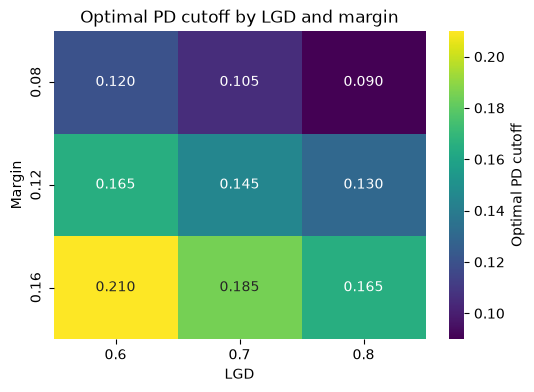

In [8]:
pivot = grid.pivot(index="margin", columns="lgd", values="best_cutoff")
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "Optimal PD cutoff"}, ax=ax)
ax.set(xlabel="LGD", ylabel="Margin", title="Optimal PD cutoff by LGD and margin")
fig.savefig(FIG_DIR / "cr06_sensitivity.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Summary

- At the base case (LGD 0.80, margin 0.12), the optimal cutoff is the breakeven PD of 0.130. It
  approves about 44% of loans. Approving every loan has negative expected profit.
- The optimal cutoff moves a lot with the assumptions: 0.09 to 0.21 across the grid. A lower
  LGD or a higher margin widens the approval band. Set the cutoff from a real LGD and margin.
- Expected profit is about 1.8 times realized profit at the optimum. The challenger under-predicts
  defaults on 2015 to 2016 (mean PD 0.171 vs observed bad rate 0.215), which matches the drift in
  CR05. Recalibrate before using expected profit for a live cutoff.
- Realized profit uses resolved loans only. Loans still open in 2016 are excluded, and they are
  likely riskier, so realized profit is somewhat optimistic in absolute terms.
- LGD and margin are assumptions. This analysis does not estimate them from data.